# Predicting PM2.5 on the analysis grid

Phase L. Apply the definitive model of notebook 09 (a Ridge regression on the satellite and weather features) to every cell and month of the grid table assembled in notebook 10, so that there is a PM2.5 estimate where there is no station. Each prediction comes with an uncertainty band and two warning indicators, because none of them is a calibrated interval and the model is applied in places that may be unlike the stations it learned from.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import yaml

import monitoring_deserts.models.predict as predict

## Configuration

Read the general project config and the model and grid metadata of the previous notebooks.

In [3]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

MODELS_DIR = Path(gen_config["data_dir"]["models"])
PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
MAPS_DIR = Path(gen_config["output_dir"]["maps"]) / "grid_predictions"
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "grid_predictions"
MAPS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# The definitive model and its features, as recorded by notebook 09
with open("../configs/model_training_metadata.yaml") as f:
    definitive_model = yaml.safe_load(f)["definitive_model"]
FEATURES = definitive_model["features"]

# The analysis grid, for the maps
analysis_grid = gpd.read_parquet(PROCESSED_DATA_DIR / "grid.parquet")

BAND_LEVEL = 0.9 # share of held-out residuals the uncertainty band contains

## Outline

1. ~~**Step 1 - Load the model and the grid table.** Load the Ridge pipeline, the Random Forest (used only as a second opinion, see Step 3) and the grid features from notebook 10. Check that the grid table has exactly the features the model was trained on, and find the rows where every feature is present: only those can be predicted.~~
2. ~~**Step 2 - Point predictions.** Predict `log1p_pm25` for the complete rows in chunks and back-transform to micrograms per cubic metre. A linear model can return negative values after the back-transform; they are clipped at zero and counted.~~
3. ~~**Step 3 - Uncertainty and warning indicators.** The tree-spread estimate of the plan does not exist for a linear model, so three things replace it: (a) a band from the spatial out-of-fold residuals of the Ridge, with its coverage by fold; (b) the disagreement between the Ridge and the Random Forest in each cell; (c) the number of features of each row that lie outside the range of the training stations.~~
4. ~~**Step 4 - Assemble and save.** One row per cell and month, with the prediction, the band, the disagreement and the out-of-range count, saved to `data/processed/`. Rows that could not be predicted stay in the table, empty, so Phases M and N see the whole grid.~~
5. ~~**Step 5 - Look at it.** Maps of the mean prediction, the disagreement and the out-of-range count; the distribution of the predictions against the observed station values.~~
6. ~~**Step 6 - Save the metadata** to `configs/grid_predictions_metadata.yaml`.~~

## Step 1 - Load the model and the grid table

The Ridge pipeline was refitted on every station-month by the search in notebook 09, so it is already the model trained on all the data. Cross-validation was for evaluation; this is the deployed model.

In [4]:
ridge = joblib.load(MODELS_DIR / "ridge_best.joblib")
forest = joblib.load(MODELS_DIR / "random_forest.joblib")

# The grid table must have exactly the features the models were trained on, in the same order
assert list(ridge.feature_names_in_) == FEATURES, "Ridge was trained on different features"
assert list(forest.feature_names_in_) == FEATURES, "Random Forest was trained on different features"

master_grid_df = pd.read_parquet(PROCESSED_DATA_DIR / "master_grid_df.parquet", columns=["cell_id", "month"] + FEATURES)

complete = master_grid_df[FEATURES].notna().all(axis=1)
print(f"{len(master_grid_df):,} cell-months, {complete.sum():,} ({complete.mean():.2%}) with every feature present")
master_grid_df[FEATURES].isna().sum().rename("missing").to_frame().T

6,959,040 cell-months, 6,959,040 (100.00%) with every feature present


,no2,aai,total_precipitation,temperature,dew_point,u_wind,v_wind,wind_magnitude,boundary_layer_height,surface_pressure,relative_humidity,sin_month,cos_month
missing,0,0,0,0,0,0,0,0,0,0,0,0,0


## Step 2 - Point predictions

The target of the model is `log1p(PM2.5)`, so the prediction is back-transformed with `np.expm1`. Predictions below zero on the original scale are not concentrations: they are set to zero and counted.

In [5]:
grid_X = master_grid_df.loc[complete, FEATURES]

log_ridge = predict.predict_in_chunks(ridge, grid_X)
pm25_ridge, n_clipped = predict.to_ugm3(log_ridge)

print(f"{len(pm25_ridge):,} predictions, {n_clipped:,} ({n_clipped / len(pm25_ridge):.3%}) were below zero and are set to zero")
pd.Series(pm25_ridge).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("predicted PM2.5 (ug/m3)").T

6,959,040 predictions, 0 (0.000%) were below zero and are set to zero


,count,mean,std,min,5%,25%,50%,75%,95%,max
predicted PM2.5 (ug/m3),6959040.0,34.099679,16.958004,6.982067,12.502546,21.039866,31.935601,43.427299,64.326043,208.008413


## Step 3 - Uncertainty and warning indicators

**(a) Residual band.** The spatial cross-validation gave one out-of-fold prediction for every station-month, each made by a model that had not seen that station's region. The quantiles of the residuals (observed minus predicted, on the log scale the model works on) give a band: add the lower and upper quantile to a prediction and it contained the stated share of held-out observations. It is one width for the whole grid, taken from where the stations are, so it cannot know that a cell is unusual. The coverage by fold shows how uneven that is.

In [6]:
oof = pd.read_parquet(MODELS_DIR / "oof_predictions.parquet")
oof_log_obs = np.log1p(oof["pm25_obs"].to_numpy())
oof_log_pred = np.log1p(oof["pm25_ridge_spatial_oof"].to_numpy()) # the log-scale prediction, even where its back-transform is negative

band_lower, band_upper = predict.residual_offsets(oof_log_obs, oof_log_pred, level=BAND_LEVEL)

inside_band = (oof_log_obs >= oof_log_pred + band_lower) & (oof_log_obs <= oof_log_pred + band_upper)
coverage_by_fold = pd.Series(inside_band).groupby(oof["spatial_fold"].to_numpy()).mean().rename("share_inside_band")

print(f"Band on the log1p scale: prediction {band_lower:+.3f} to {band_upper:+.3f} ({BAND_LEVEL:.0%} of the {len(oof):,} held-out residuals)")
coverage_by_fold.to_frame().style.format("{:.1%}")

Band on the log1p scale: prediction -0.696 to +0.738 (90% of the 5,222 held-out residuals)


,share_inside_band
0,78.0%
1,92.0%
2,88.0%
3,89.9%
4,92.7%
5,95.3%
6,88.5%
7,95.4%


**(b) Disagreement with the Random Forest.** The forest is a very different model (piecewise constant, bounded by the training range). Where it and the Ridge give different answers for the same cell, at least one of them is extrapolating or missing something. This is a warning indicator, not an error estimate: both models can be wrong in the same direction.

In [7]:
log_forest = predict.predict_in_chunks(forest, grid_X)
disagreement = np.abs(log_ridge - log_forest) # log scale

pd.Series(disagreement).describe(percentiles=[0.5, 0.9, 0.99]).to_frame("|ridge - forest| (log1p)").T

,count,mean,std,min,50%,90%,99%,max
|ridge - forest| (log1p),6959040.0,0.200604,0.175608,1.806345e-08,0.151249,0.462743,0.742054,1.443387


**(c) Features outside the range of the stations.** For each row, how many of the continuous features lie below the 1st or above the 99th percentile of the training stations. The month encodings are left out because they take the same twelve values everywhere. A high count marks a row unlike the training data in several features at once, which is where a linear model extrapolates.

In [8]:
station_features = pd.read_parquet(PROCESSED_DATA_DIR / "master_station_df.parquet")
range_features = [feature for feature in FEATURES if feature not in ("sin_month", "cos_month")]

n_outside, station_ranges = predict.count_features_outside_range(grid_X[range_features], station_features)

display(station_ranges)
pd.Series(n_outside).value_counts(normalize=True).sort_index().rename("share of predicted rows").to_frame().style.format("{:.2%}")

,lower,upper
no2,0.000014,0.000223
aai,-0.909204,1.135285
total_precipitation,0.000000,0.018234
temperature,285.419735,307.458368
dew_point,280.649677,299.908212
u_wind,-2.473978,4.442316
v_wind,-2.130699,2.977993
wind_magnitude,0.203254,4.937156
boundary_layer_height,209.991982,1181.224897
surface_pressure,90485.991600,101246.421764


,share of predicted rows
0,23.53%
1,16.15%
2,12.46%
3,15.82%
4,21.40%
5,8.00%
6,2.42%
7,0.20%
8,0.02%
9,0.00%


## Step 4 - Assemble and save

Every cell and month of the grid stays in the table, so the columns line up with the grid for the next phases; the rows that could not be predicted have empty values. The file is parquet, not the CSV the plan names: about 7 million rows.

In [9]:
lower_ugm3, _ = predict.to_ugm3(log_ridge + band_lower)
upper_ugm3, _ = predict.to_ugm3(log_ridge + band_upper)

grid_predictions = master_grid_df[["cell_id", "month"]].copy()
columns = {
    "predicted_pm25": pm25_ridge,
    "pm25_lower": lower_ugm3,
    "pm25_upper": upper_ugm3,
    "model_disagreement_log": disagreement,
    "n_features_out_of_range": n_outside.astype("float32"), # float so the rows without a prediction can be empty
}
for name, values in columns.items():
    grid_predictions[name] = np.float32(np.nan)
    grid_predictions.loc[complete, name] = values.astype("float32")

PREDICTIONS_PATH = PROCESSED_DATA_DIR / "grid_predictions.parquet"
grid_predictions.to_parquet(PREDICTIONS_PATH)
print(f"{len(grid_predictions):,} rows saved to {PREDICTIONS_PATH}")
grid_predictions.head()

6,959,040 rows saved to ../data/processed/grid_predictions.parquet


,cell_id,month,predicted_pm25,pm25_lower,pm25_upper,model_disagreement_log,n_features_out_of_range
0,0,2025-03,34.908676,16.894466,74.123726,0.112746,3.0
1,1,2025-03,34.724972,16.802921,73.739410,0.107732,3.0
2,2,2025-03,34.902462,16.891369,74.110725,0.111983,3.0
3,3,2025-03,35.766991,17.322193,75.919395,0.134348,3.0
4,4,2025-03,36.486149,17.680571,77.423920,0.150837,3.0


## Step 5 - Look at it

The grid's axes and the position of every cell in the raster are built as in notebooks 06 and 10. The maps show the mean over the months of each cell.

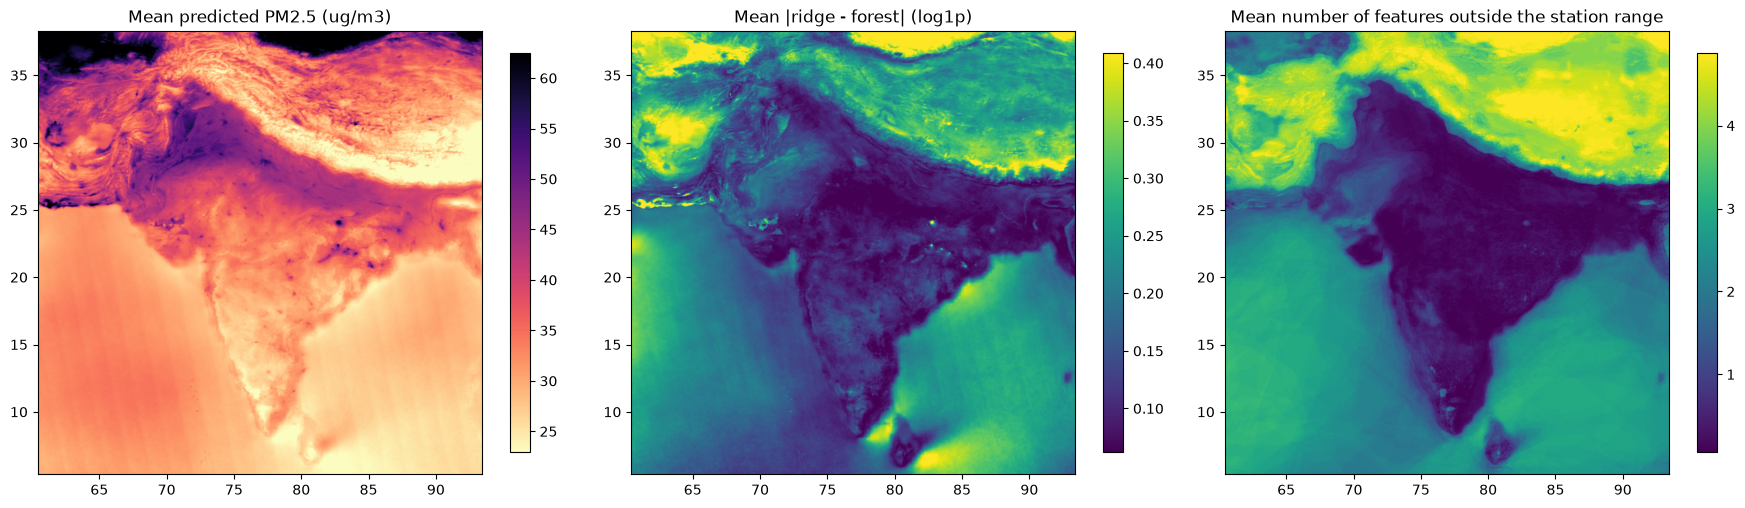

In [10]:
CELL_SIZE = gen_config["grid_cell_size_deg"]
grid_lons = np.sort(analysis_grid["centroid_lon"].round(9).unique())
grid_lats = np.sort(analysis_grid["centroid_lat"].round(9).unique())
col = np.searchsorted(grid_lons, analysis_grid["centroid_lon"].round(9).values)
row = len(grid_lats) - 1 - np.searchsorted(grid_lats, analysis_grid["centroid_lat"].round(9).values)
extent = [grid_lons[0] - CELL_SIZE / 2, grid_lons[-1] + CELL_SIZE / 2, grid_lats[0] - CELL_SIZE / 2, grid_lats[-1] + CELL_SIZE / 2]


def cell_means_to_raster(column):
    """Mean over the months of one prediction column, as a north-up raster (NaN where nothing was predicted)."""
    means = grid_predictions.groupby("cell_id")[column].mean().reindex(analysis_grid["cell_id"].values)
    raster = np.full((len(grid_lats), len(grid_lons)), np.nan)
    raster[row, col] = means.values
    return raster


panels = {
    "predicted_pm25": ("Mean predicted PM2.5 (ug/m3)", "magma_r"),
    "model_disagreement_log": ("Mean |ridge - forest| (log1p)", "viridis"),
    "n_features_out_of_range": ("Mean number of features outside the station range", "viridis"),
}
fig, axes = plt.subplots(1, len(panels), figsize=(18, 6))
for ax, (column, (title, cmap)) in zip(axes, panels.items()):
    raster = cell_means_to_raster(column)
    low, high = np.nanquantile(raster, [0.02, 0.98])
    image = ax.imshow(raster, extent=extent, vmin=low, vmax=high, cmap=cmap)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(MAPS_DIR / "grid_predictions_mean.png", dpi=150)
plt.show()

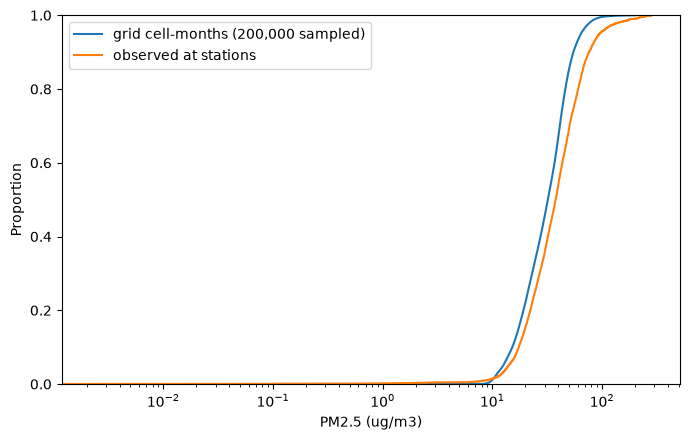

In [11]:
# Distribution of the predictions against the observed station values
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.ecdfplot(grid_predictions["predicted_pm25"].dropna().sample(200_000, random_state=42), ax=ax, label="grid cell-months (200,000 sampled)")
sns.ecdfplot(station_features["pm25"].dropna(), ax=ax, label="observed at stations")
ax.set_xlabel("PM2.5 (ug/m3)")
ax.set_xscale("log")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "predicted_vs_observed_distribution.png", dpi=150)
plt.show()

Reading notes: the maps are for a first look at plausibility (is the polluted plain polluted, are the mountains clean); the proper comparison with an independent product is Phase O. A cell that is pale on the first map but bright on the second or third map is one whose prediction should not be taken at face value. The band is one width everywhere, so it says nothing about where the model is more uncertain: that is what the disagreement and the out-of-range count are for. Predictions are compressed towards the middle at high values (the cross-validation showed this for fold 0), so statements about the most polluted cells should be about their rank, not their level. The plot uses a logarithmic axis because the values span two orders of magnitude.

## Step 6 - Save the metadata

In [12]:
metadata = {
    "model": definitive_model["model"],
    "model_file": definitive_model["saved_model"],
    "second_opinion_model": "Random Forest, data/models/random_forest.joblib (disagreement indicator only)",
    "features": list(FEATURES),
    "target_transform": "log1p; predictions back-transformed with expm1 and clipped at zero",
    "n_rows": int(len(grid_predictions)),
    "n_rows_predicted": int(complete.sum()),
    "n_clipped_at_zero": int(n_clipped),
    "residual_band": {
        "level": BAND_LEVEL,
        "source": "spatial out-of-fold residuals of the Ridge on the log1p scale (data/models/oof_predictions.parquet)",
        "lower_offset_log1p": float(band_lower),
        "upper_offset_log1p": float(band_upper),
        "share_inside_band_by_fold": {int(fold): float(share) for fold, share in coverage_by_fold.items()},
        "note": "One width for the whole grid; not a calibrated prediction interval.",
    },
    "out_of_range_check": {
        "reference": "data/processed/master_station_df.parquet",
        "quantiles": [0.01, 0.99],
        "features_checked": list(range_features),
        "limits": {feature: {"lower": float(limits["lower"]), "upper": float(limits["upper"])} for feature, limits in station_ranges.iterrows()},
    },
    "file": str(PREDICTIONS_PATH),
    "library_versions": {"scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
with open("../configs/grid_predictions_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)